In [1]:
%load_ext autoreload
%autoreload 2

import math
import numpy as np
import matplotlib.pyplot as plt

import beam_numpy as bn

rng = np.random.default_rng(2026)

GeV = 1.0
MeV = 0.001

M_pi = 139.57039 * MeV
M_mu = 105.65837 * MeV
M_K = 493.68 * MeV

In [2]:
directions = bn.random_direction(100_000, rng)

print(directions.shape)
print("Средние компоненты:", directions.mean(axis=1))

assert np.allclose(
    np.sum(directions**2, axis=0),
    1
)

(3, 100000)
Средние компоненты: [ 0.00176123  0.00213587 -0.00314944]


In [3]:
%%time

p_nu = bn.neutrino_beam_z(
    1_000_000,
    M_pi,
    10 * GeV,
    M_mu,
    rng
)

CPU times: total: 234 ms
Wall time: 232 ms


In [4]:
print(p_nu.shape)
print(p_nu[:, :3])

(4, 1000000)
[[ 1.04000029  0.80010048  0.67954779]
 [-0.00600363  0.02315666  0.01183091]
 [ 0.02800011 -0.01400302  0.02258574]
 [ 1.03960596  0.79964271  0.6790693 ]]


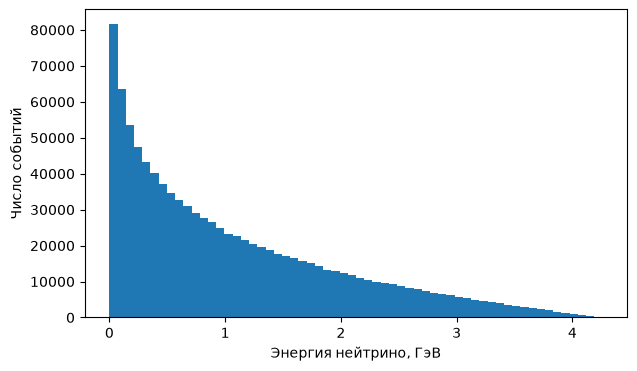

In [5]:
plt.figure(figsize=(7, 4))

plt.hist(p_nu[0], bins=60)

plt.xlabel("Энергия нейтрино, ГэВ")
plt.ylabel("Число событий")

plt.show()

In [6]:
p_pions = bn.hadron_beam(
    1_000_000, M_pi, 10 * GeV,
    rng, theta_rms=0.1
)

p_kaons = bn.hadron_beam(
    1_000_000, M_K, 10 * GeV,
    rng, theta_rms=0.1
)

p_nu_pi, p_mu_pi = bn.decay_beam(
    p_pions, M_mu, rng
)

p_nu_K, p_mu_K = bn.decay_beam(
    p_kaons, M_mu, rng
)

In [7]:
#Проверяем физ.законы
assert np.allclose(
    p_nu_pi + p_mu_pi,
    p_pions,
    atol=1e-8
)

nu_mass_squared = (
    p_nu_pi[0]**2
    - np.sum(p_nu_pi[1:]**2, axis=0)
)

mu_mass_squared = (
    p_mu_pi[0]**2
    - np.sum(p_mu_pi[1:]**2, axis=0)
)

assert np.allclose(nu_mass_squared, 0, atol=1e-8)
assert np.allclose(mu_mass_squared, M_mu**2, atol=1e-8)

assert np.allclose(
    bn.lorentz_boost(np.zeros((3, 1)), p_pions),
    p_pions
)

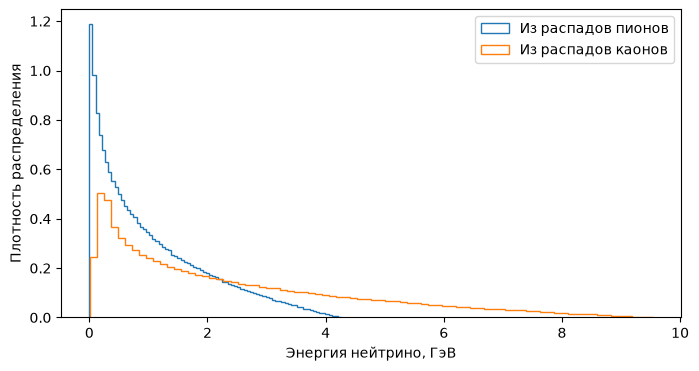

In [8]:
#Строим сравнение нейтрино
plt.figure(figsize=(8, 4))

plt.hist(
    p_nu_pi[0],
    bins=80,
    density=True,
    histtype="step",
    label="Из распадов пионов"
)

plt.hist(
    p_nu_K[0],
    bins=80,
    density=True,
    histtype="step",
    label="Из распадов каонов"
)

plt.xlabel("Энергия нейтрино, ГэВ")
plt.ylabel("Плотность распределения")
plt.legend()

plt.show()

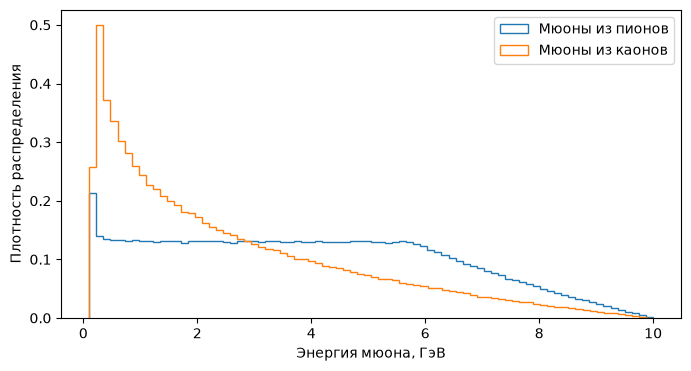

In [9]:
#Строим сравнение мюонов
plt.figure(figsize=(8, 4))

plt.hist(
    p_mu_pi[0],
    bins=80,
    density=True,
    histtype="step",
    label="Мюоны из пионов"
)

plt.hist(
    p_mu_K[0],
    bins=80,
    density=True,
    histtype="step",
    label="Мюоны из каонов"
)

plt.xlabel("Энергия мюона, ГэВ")
plt.ylabel("Плотность распределения")
plt.legend()

plt.show()

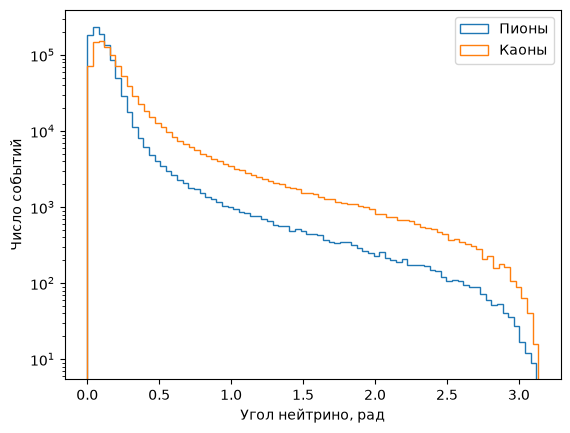

In [10]:
theta_pi = np.arctan2(
    np.sqrt(p_nu_pi[1]**2 + p_nu_pi[2]**2),
    p_nu_pi[3]
)

theta_K = np.arctan2(
    np.sqrt(p_nu_K[1]**2 + p_nu_K[2]**2),
    p_nu_K[3]
)

plt.hist(theta_pi, bins=80, histtype="step", label="Пионы")
plt.hist(theta_K, bins=80, histtype="step", label="Каоны")

plt.xlabel("Угол нейтрино, рад")
plt.ylabel("Число событий")
plt.yscale("log")
plt.legend()

plt.show()

In [11]:
def normal_pdf(x, mu=0, sigma=1):
    return (
        np.exp(-0.5 * ((x - mu) / sigma)**2)
        / (sigma * np.sqrt(2 * np.pi))
    )

In [12]:
P_parent = np.linalg.norm(
    p_pions[1:],
    axis=0
)

In [13]:
mu = 7.0
sigma = 1.0
Pmax = 10.0

Z = 0.5 * (
    math.erf((Pmax - mu) / (sigma * np.sqrt(2)))
    - math.erf((0 - mu) / (sigma * np.sqrt(2)))
)

weights = (
    Pmax * normal_pdf(P_parent, mu, sigma) / Z
)

print("Сумма весов:", weights.sum())
print("Число событий:", len(weights))

Сумма весов: 998828.4257903046
Число событий: 1000000


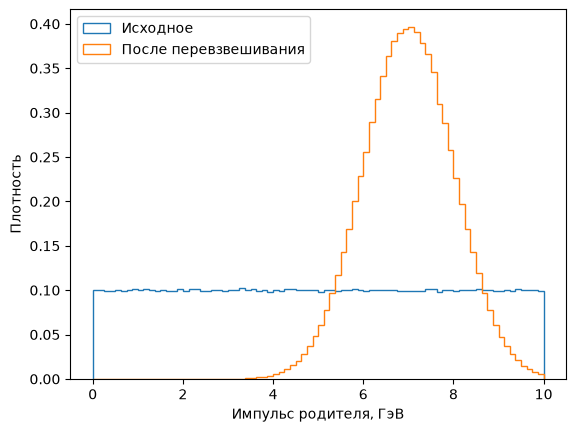

In [14]:
plt.hist(
    P_parent,
    bins=80,
    density=True,
    histtype="step",
    label="Исходное"
)

plt.hist(
    P_parent,
    bins=80,
    weights=weights,
    density=True,
    histtype="step",
    label="После перевзвешивания"
)

plt.xlabel("Импульс родителя, ГэВ")
plt.ylabel("Плотность")
plt.legend()

plt.show()

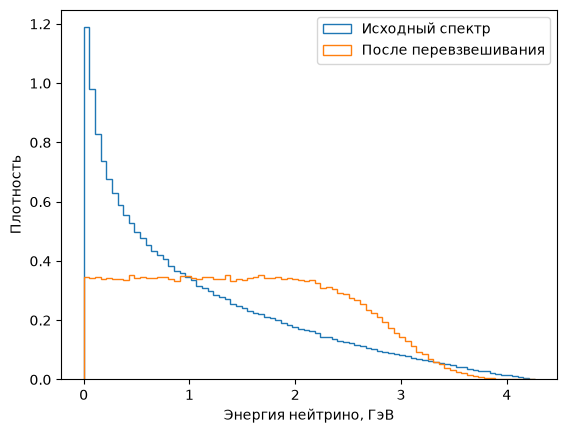

In [15]:
plt.hist(
    p_nu_pi[0],
    bins=80,
    density=True,
    histtype="step",
    label="Исходный спектр"
)

plt.hist(
    p_nu_pi[0],
    bins=80,
    weights=weights,
    density=True,
    histtype="step",
    label="После перевзвешивания"
)

plt.xlabel("Энергия нейтрино, ГэВ")
plt.ylabel("Плотность")
plt.legend()

plt.show()

In [16]:
print("Средний импульс до:", np.mean(P_parent))

print(
    "Средний импульс после:",
    np.average(P_parent, weights=weights)
)

print("Средняя энергия нейтрино до:", np.mean(p_nu_pi[0]))

print(
    "Средняя энергия нейтрино после:",
    np.average(p_nu_pi[0], weights=weights)
)

Средний импульс до: 4.999242859615804
Средний импульс после: 6.995330491272104
Средняя энергия нейтрино до: 1.0681451615771218
Средняя энергия нейтрино после: 1.490963939234202
